# 06: RQ3, the multimodal extension (wrist signals)

RQ3 asks whether the signals recorded alongside the EEG carry anything across participants where EEG alone does not. The Empatica E4 on each participant's wrist recorded heart rate and electrodermal activity through every FatigueSet session. The design runs four arms on the same windows and the same folds as Week 2: EEG only (the stored Week 2 numbers), peripheral only (mean heart rate, electrodermal mean, slope and rise count, plus validity indicators), combined, and an indicators-only arm that sees nothing but which windows have valid wrist data.

That last arm is the shortcut ceiling, and it matters here: wrist data loss was not random. 59 of the 60 windows with unusable wrist data are fatigued class (two participants' bands stopped early in their late blocks), so before I believe any peripheral score I need to know how much of it the missingness pattern alone can buy.

## 0. Setup

In [1]:
# Setup. The pipeline in src/ is the engine; this notebook is a front door
# to it. Here I find the repository root, put the frozen modules and the
# pinned libraries on the path, and patch one NumPy rename.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

if not hasattr(np, "trapz"):
    # NumPy 2.x renamed trapz to trapezoid. The frozen band-power module
    # still calls np.trapz, so I alias it here instead of editing frozen code.
    np.trapz = np.trapezoid


def find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "features" / "bandpower.py").exists():
            return cand
    raise FileNotFoundError("repository root not found above the working directory")


ROOT = find_root()
for extra in (str(ROOT), str(Path.home() / "workspace" / ".pylibs")):
    if Path(extra).exists() and extra not in sys.path:
        sys.path.insert(0, extra)

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
PROC = ROOT / "data" / "processed"
pd.set_option("display.width", 120)
print("repository root:", ROOT)

repository root: /home/hatch/workspace/thesis-fatigue


## 1. The arms, leave-one-participant-out

In [2]:
arms = pd.read_csv(TAB / "rq3_arm_summary.csv")
keep = arms[(arms.pool == "keepall") & (arms.protocol == "lopo")]
keep[["arm", "n_participants", "balanced_accuracy_mean", "balanced_accuracy_lo",
      "balanced_accuracy_hi", "roc_auc_mean"]]

,arm,n_participants,balanced_accuracy_mean,balanced_accuracy_lo,balanced_accuracy_hi,roc_auc_mean
4,combined,11,0.737309,0.635855,0.837910,0.801798
7,eeg,11,0.507804,0.471295,0.541935,0.540496
8,indicators,11,0.538962,0.500000,0.594510,0.538962
9,peripheral,11,0.740718,0.632510,0.850624,0.835905


In [3]:
contrasts = pd.read_csv(TAB / "rq3_contrasts.csv")
contrasts[contrasts.contrast.isin([
    "peripheral - indicators (keepall LOPO)",
    "combined - EEG-only stored Week 2 (keepall LOPO)",
])][["contrast", "n_participants", "diff_mean", "diff_lo", "diff_hi"]]

,contrast,n_participants,diff_mean,diff_lo,diff_hi
0,peripheral - indicators (keepall LOPO),11,0.201755,0.085084,0.314314
1,combined - EEG-only stored Week 2 (keepall LOPO),11,0.229773,0.128325,0.332381


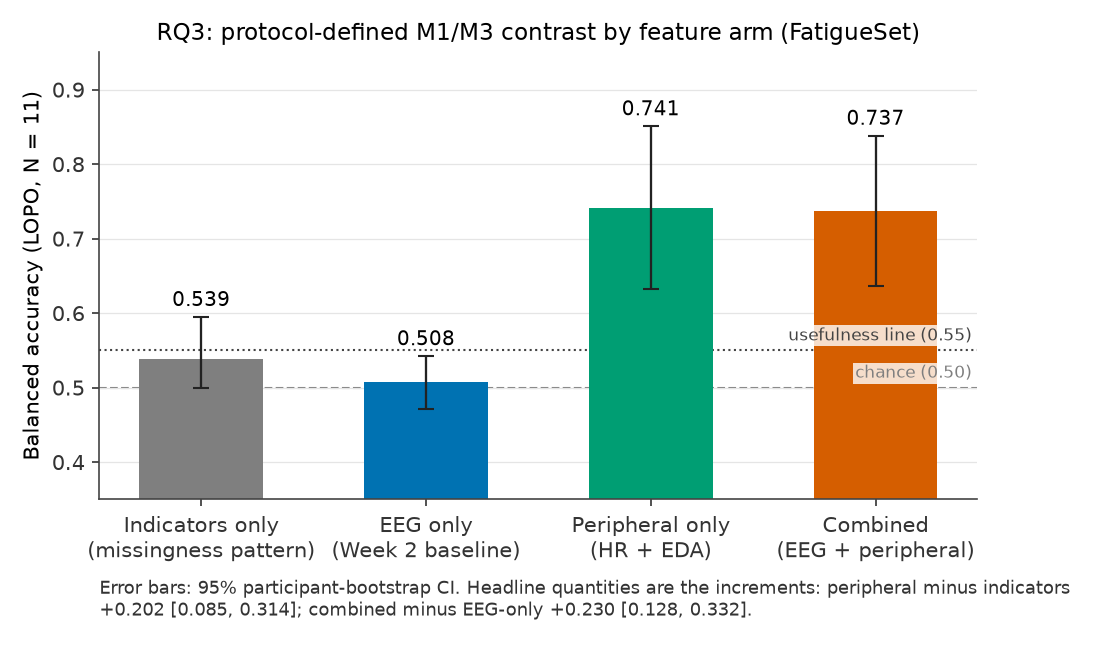

In [4]:
from IPython.display import Image

Image(filename=str(FIG / "fig_rq3_arms.png"))

## 2. The claim, with its confound inside it

Peripheral features score 0.741 [0.633, 0.851] against 0.539 [0.500, 0.595] for the indicators-only arm, and those two numbers are always reported together. The increments are +0.202 [0.085, 0.314] over the missingness shortcut and +0.230 [0.128, 0.332] over EEG only, and they hold on the restricted pool of windows where the wrist data is complete.

The locked claim for RQ3 is:

**peripheral features recover the protocol-defined M1/M3 contrast across participants, and the design cannot separate fatigue from exercise-related physiology**

The early block sits before the treadmill and the late block after it, so a heart-rate and skin-conductance model can be reading exercise aftermath rather than fatigue, and this design cannot separate the two. That is why the claim is stated the way it is, and why nothing in this notebook calls the result fatigue detection. One consistency note: the within-subject tier is weak (peripheral 0.549, at chance imprecisely), which is the opposite ordering from a personal fatigue signature and the expected ordering for a shared physiological response to exercise. I report that as the more parsimonious reading, not as a finding.

## 3. A descriptive check: heart rate by treadmill intensity

No model, no intervals, no inference attached. The late-minus-early mean heart-rate gap, split by the day's treadmill intensity:

In [5]:
pd.read_csv(TAB / "rq3_hr_by_intensity.csv")

,intensity,n_windows_hr_usable_m1,hr_mean_m1_bpm,n_windows_hr_usable_m3,hr_mean_m3_bpm,hr_m3_minus_m1_bpm
0,low,119,71.640912,88,70.294074,-1.346838
1,medium,234,72.424517,200,85.693863,13.269346
2,high,210,77.288269,142,95.449218,18.160949


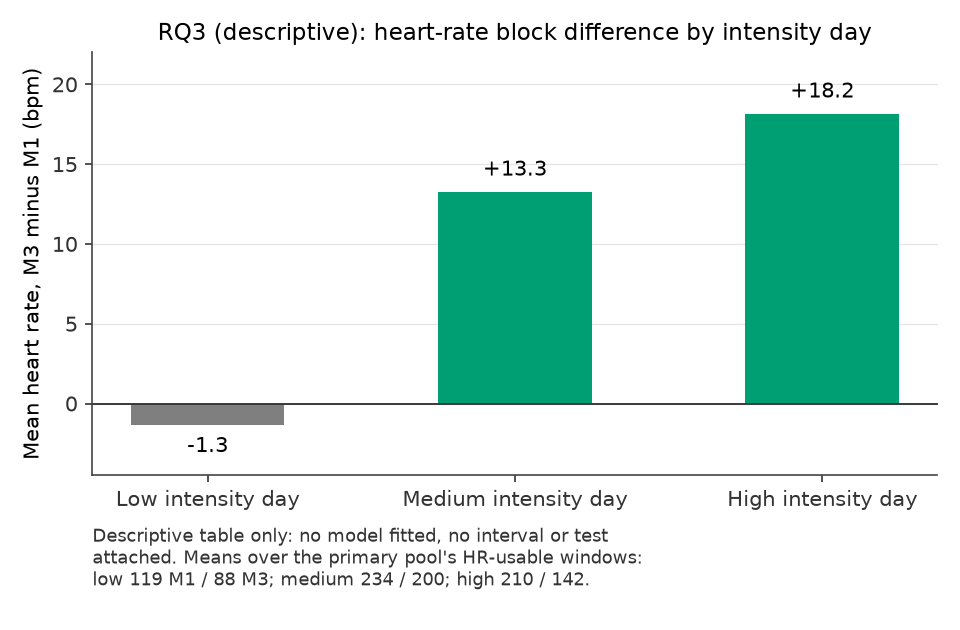

In [6]:
Image(filename=str(FIG / "fig_rq3_hr_intensity.png"))

The gap scales with how hard the participant exercised: minus 1.3 bpm on low days, +13.3 on medium days, +18.2 on high days. The feature family the model leans on most visibly tracks exercise load, which is exactly the confound the locked claim carries.

One exclusion, decided before modelling: heart-rate variability features are not used. The inter-beat-interval stream has beats undetected for stretches of minutes, and only about a third of windows hold enough usable beats to compute a variability feature, so the HR arm is mean heart rate only and no variability claim is made anywhere in this project.

Full write-up: `docs/rq3_results.md`. The data inventory behind the arms: `docs/RQ3_INVENTORY.md`.